In [1]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [8]:
import pandas as pd
df = pd.read_csv("/content/drive/MyDrive/SEMESTER 7/Coffe_sales.csv")
df.head()

,hour_of_day,cash_type,money,coffee_name,Time_of_Day,Weekday,Month_name,Weekdaysort,Monthsort,Date,Time
0,10,card,38.7,Latte,Morning,Fri,Mar,5,3,2024-03-01,10:15:50.520000
1,12,card,38.7,Hot Chocolate,Afternoon,Fri,Mar,5,3,2024-03-01,12:19:22.539000
2,12,card,38.7,Hot Chocolate,Afternoon,Fri,Mar,5,3,2024-03-01,12:20:18.089000
3,13,card,28.9,Americano,Afternoon,Fri,Mar,5,3,2024-03-01,13:46:33.006000
4,13,card,38.7,Latte,Afternoon,Fri,Mar,5,3,2024-03-01,13:48:14.626000


In [9]:
df.tail()

,hour_of_day,cash_type,money,coffee_name,Time_of_Day,Weekday,Month_name,Weekdaysort,Monthsort,Date,Time
3542,10,card,35.76,Cappuccino,Morning,Sun,Mar,7,3,2025-03-23,10:34:54.894000
3543,14,card,35.76,Cocoa,Afternoon,Sun,Mar,7,3,2025-03-23,14:43:37.362000
3544,14,card,35.76,Cocoa,Afternoon,Sun,Mar,7,3,2025-03-23,14:44:16.864000
3545,15,card,25.96,Americano,Afternoon,Sun,Mar,7,3,2025-03-23,15:47:28.723000
3546,18,card,35.76,Latte,Night,Sun,Mar,7,3,2025-03-23,18:11:38.635000


In [10]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 3547 entries, 0 to 3546
Data columns (total 11 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   hour_of_day  3547 non-null   int64  
 1   cash_type    3547 non-null   object 
 2   money        3547 non-null   float64
 3   coffee_name  3547 non-null   object 
 4   Time_of_Day  3547 non-null   object 
 5   Weekday      3547 non-null   object 
 6   Month_name   3547 non-null   object 
 7   Weekdaysort  3547 non-null   int64  
 8   Monthsort    3547 non-null   int64  
 9   Date         3547 non-null   object 
 10  Time         3547 non-null   object 
dtypes: float64(1), int64(3), object(7)
memory usage: 304.9+ KB


In [11]:
# Deteksi Missing Value
print(df.isnull().sum())

hour_of_day    0
cash_type      0
money          0
coffee_name    0
Time_of_Day    0
Weekday        0
Month_name     0
Weekdaysort    0
Monthsort      0
Date           0
Time           0
dtype: int64


In [12]:
print(df.duplicated().sum())

0


In [ ]:
# Hitung total penjualan per hari
df_daily = df.groupby('Date').size().reset_index(name='total_penjualan')

# Mengurutkan berdasarkan tanggal
df_daily = df_daily.sort_values('Date').reset_index(drop=True)

# Tampilkan 5 baris pertama
df_daily

,Date,total_penjualan
0,2024-03-01,11
1,2024-03-02,6
2,2024-03-03,9
3,2024-03-04,4
4,2024-03-05,9
...,...,...
376,2025-03-19,21
377,2025-03-20,20
378,2025-03-21,20
379,2025-03-22,12


In [ ]:
print(df_daily.shape[0])

381


# coba liat ada hari yang gaada penjualannya

In [ ]:
import pandas as pd

# Pastikan Date diubah ke datetime dulu
df['Date'] = pd.to_datetime(df['Date'])

# Bikin agregasi harian
df_daily = df.groupby('Date').size().reset_index(name='total_penjualan')

# Bikin range tanggal lengkap
full_range = pd.date_range(start=df['Date'].min(), end=df['Date'].max(), freq='D')

# Terapkan reindex
df_daily_complete = df_daily.set_index('Date').reindex(full_range, fill_value=0).reset_index()
df_daily_complete.columns = ['Date', 'total_penjualan']

# Filter hari yang penjualannya BENAR-BENAR 0 (Toko Tutup/Libur)
zero_daily = df_daily_complete[df_daily_complete['total_penjualan'] == 0]

print("Jumlah hari tanpa penjualan sama sekali:", len(zero_daily))
print(zero_daily)

Jumlah hari tanpa penjualan sama sekali: 7
          Date  total_penjualan
61  2024-05-01                0
64  2024-05-04                0
65  2024-05-05                0
271 2024-11-27                0
306 2025-01-01                0
324 2025-01-19                0
328 2025-01-23                0


# INI PAKE data wrangling (reindexing, imputasi dengan nilai 0, imputasi forward fill, imputasi interpolasi linier)

In [ ]:
import pandas as pd

# 1. Pastikan Date berformat datetime dan buat agregasi harian
df['Date'] = pd.to_datetime(df['Date'])
df_daily = df.groupby('Date').size().reset_index(name='total_penjualan')

# 2. Reindex tanggal lengkap (murni dengan NaN di tanggal libur)
full_range = pd.date_range(start=df_daily['Date'].min(), end=df_daily['Date'].max(), freq='D')
df_wrangled = df_daily.set_index('Date').reindex(full_range).reset_index()
df_wrangled.columns = ['Date', 'total_penjualan']

# 3. Buat kolom untuk masing-masing metode imputasi dalam 1 DataFrame
df_wrangled['sales_zero'] = df_wrangled['total_penjualan'].fillna(0)
df_wrangled['sales_ffill'] = df_wrangled['total_penjualan'].ffill()
df_wrangled['sales_interp'] = df_wrangled['total_penjualan'].interpolate(method='linear')

# Cek hasil perbandingan di area tanggal yang tadinya kosong (NaN)
print("--- Sampel Data Hasil Wrangling & Imputasi ---")
df_wrangled

--- Sampel Data Hasil Wrangling & Imputasi ---


,Date,total_penjualan,sales_zero,sales_ffill,sales_interp
0,2024-03-01,11.0,11.0,11.0,11.0
1,2024-03-02,6.0,6.0,6.0,6.0
2,2024-03-03,9.0,9.0,9.0,9.0
3,2024-03-04,4.0,4.0,4.0,4.0
4,2024-03-05,9.0,9.0,9.0,9.0
...,...,...,...,...,...
383,2025-03-19,21.0,21.0,21.0,21.0
384,2025-03-20,20.0,20.0,20.0,20.0
385,2025-03-21,20.0,20.0,20.0,20.0
386,2025-03-22,12.0,12.0,12.0,12.0


In [ ]:
from statsmodels.tsa.stattools import adfuller, kpss
import pandas as pd

# 1. Split Data Training (80%)
split_idx = int(len(df_wrangled) * 0.85)
train_data = df_wrangled.iloc[:split_idx].copy()

metode_list = ['sales_zero', 'sales_ffill', 'sales_interp']
res_awal = []

for col in metode_list:
    s_raw = train_data[col].dropna()

    # Uji ADF
    adf_pval = adfuller(s_raw)[1]

    # Uji KPSS
    kpss_pval = kpss(s_raw, regression='c', nlags='auto')[1]

    res_awal.append({
        'Metode Imputasi': col,
        'ADF p-value': round(adf_pval, 4),
        'Status ADF': 'Stasioner' if adf_pval < 0.05 else 'Belum Stasioner',
        'KPSS p-value': round(kpss_pval, 4),
        'Status KPSS': 'Stasioner' if kpss_pval > 0.05 else 'Belum Stasioner'
    })

df_res_awal = pd.DataFrame(res_awal)
print("=== UJI STASIONERITAS AWAL (DATA ASLI) ===")
df_res_awal

=== UJI STASIONERITAS AWAL (DATA ASLI) ===


/tmp/ipykernel_102487/2479627937.py:15: FutureWarning: adfuller currently returns a plain tuple whose length depends on the store and autolag arguments. In release 0.16 or after July 2027, whichever is later, the default behavior will switch to always returning an ADFullerResult. Set result_object=True to switch now, or result_object=False to keep the current behavior and silence this warning.
  adf_pval = adfuller(s_raw)[1]
/tmp/ipykernel_102487/2479627937.py:18: InterpolationWarning: The test statistic is outside of the range of p-values available in the look-up table. The actual p-value is smaller than the p-value returned.
  kpss_pval = kpss(s_raw, regression='c', nlags='auto')[1]
/tmp/ipykernel_102487/2479627937.py:18: FutureWarning: kpss currently returns a plain tuple whose length and layout depends on the store argument (and which silently drops `lags` when store=True). In release 0.16 or after July 2027, whichever is later, the default behavior will switch to always returning 

,Metode Imputasi,ADF p-value,Status ADF,KPSS p-value,Status KPSS
0,sales_zero,0.0106,Stasioner,0.01,Belum Stasioner
1,sales_ffill,0.0042,Stasioner,0.01,Belum Stasioner
2,sales_interp,0.0051,Stasioner,0.01,Belum Stasioner


In [ ]:
res_diff = []

for col in metode_list:
    # Differencing 1 kali
    s_diff = train_data[col].diff().dropna()

    # Uji ADF Ulang
    adf_pval = adfuller(s_diff)[1]

    # Uji KPSS Ulang
    kpss_pval = kpss(s_diff, regression='c', nlags='auto')[1]

    res_diff.append({
        'Metode Imputasi': col,
        'ADF p-value (d=1)': round(adf_pval, 4),
        'Status ADF': 'Stasioner' if adf_pval < 0.05 else 'Belum Stasioner',
        'KPSS p-value (d=1)': round(kpss_pval, 4),
        'Status KPSS': 'Stasioner' if kpss_pval > 0.05 else 'Belum Stasioner'
    })

df_res_diff = pd.DataFrame(res_diff)
print("=== UJI STASIONERITAS SETELAH DIFFERENCING 1 (d=1) ===")
df_res_diff

=== UJI STASIONERITAS SETELAH DIFFERENCING 1 (d=1) ===


/tmp/ipykernel_93419/2362444615.py:8: FutureWarning: adfuller currently returns a plain tuple whose length depends on the store and autolag arguments. In release 0.16 or after July 2027, whichever is later, the default behavior will switch to always returning an ADFullerResult. Set result_object=True to switch now, or result_object=False to keep the current behavior and silence this warning.
  adf_pval = adfuller(s_diff)[1]
/tmp/ipykernel_93419/2362444615.py:11: InterpolationWarning: The test statistic is outside of the range of p-values available in the look-up table. The actual p-value is greater than the p-value returned.
  kpss_pval = kpss(s_diff, regression='c', nlags='auto')[1]
/tmp/ipykernel_93419/2362444615.py:11: FutureWarning: kpss currently returns a plain tuple whose length and layout depends on the store argument (and which silently drops `lags` when store=True). In release 0.16 or after July 2027, whichever is later, the default behavior will switch to always returning a 

,Metode Imputasi,ADF p-value (d=1),Status ADF,KPSS p-value (d=1),Status KPSS
0,sales_zero,0.0,Stasioner,0.1,Stasioner
1,sales_ffill,0.0,Stasioner,0.1,Stasioner
2,sales_interp,0.0,Stasioner,0.1,Stasioner


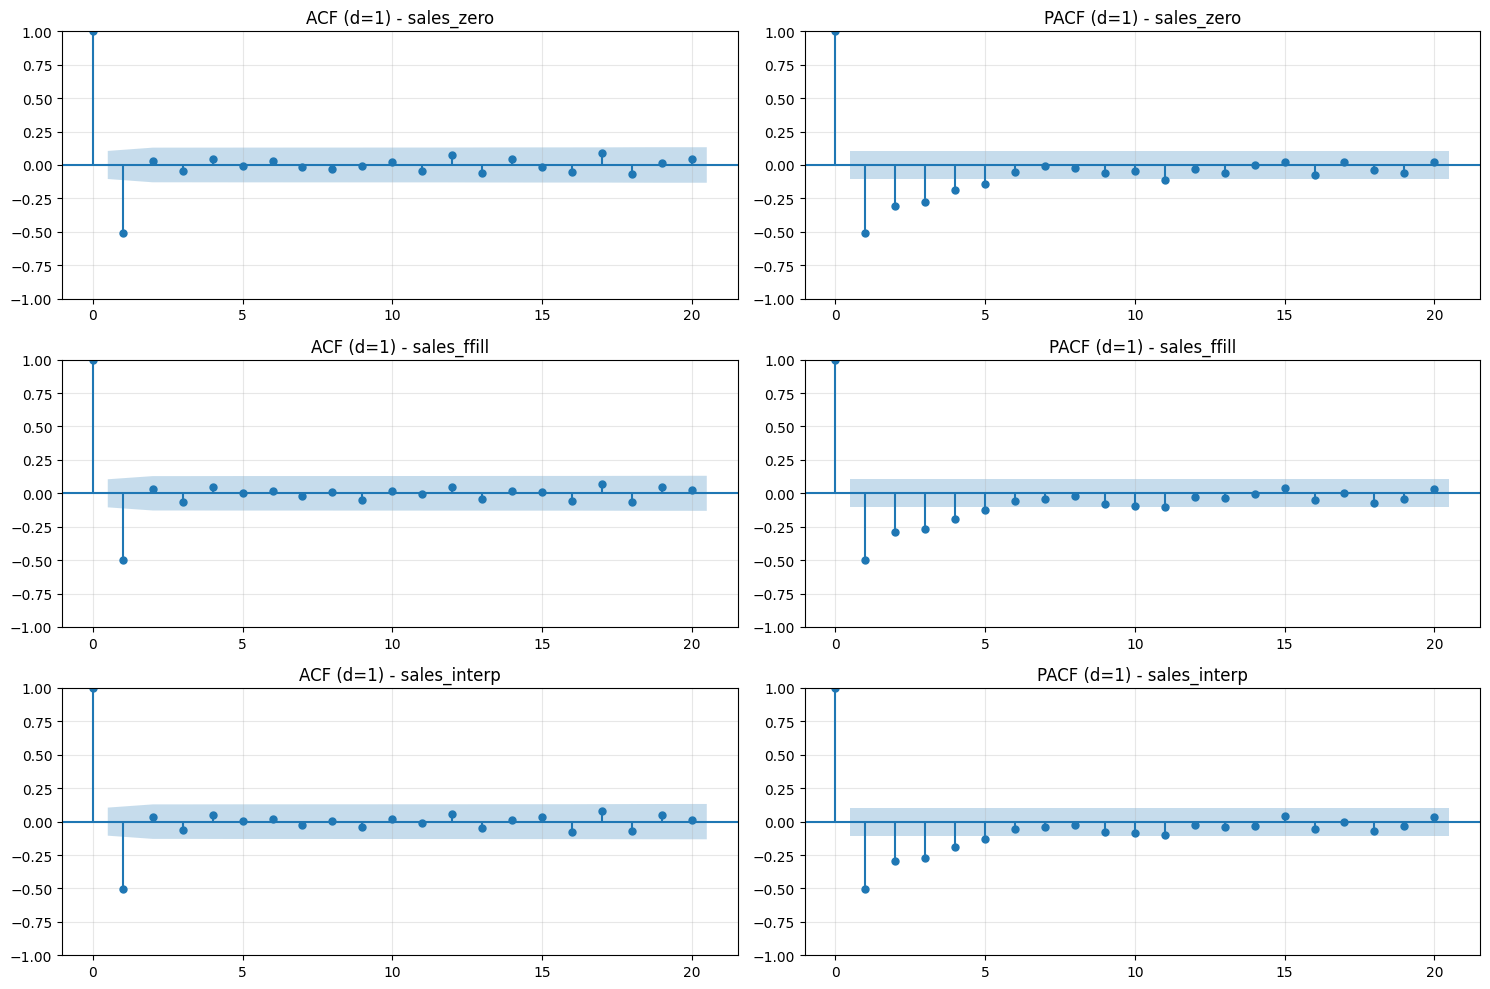

In [ ]:
import matplotlib.pyplot as plt
from statsmodels.graphics.tsaplots import plot_acf, plot_pacf

fig, axes = plt.subplots(3, 2, figsize=(15, 10))

for idx, col in enumerate(metode_list):
    # Mengambil series data yang SUDAH di-differencing 1 kali
    diff_series = train_data[col].diff().dropna()

    # Plot ACF (kiri) untuk menentukan kandidat q (MA)
    plot_acf(diff_series, ax=axes[idx, 0], lags=20, title=f'ACF (d=1) - {col}')
    axes[idx, 0].grid(True, alpha=0.3)

    # Plot PACF (kanan) untuk menentukan kandidat p (AR)
    plot_pacf(diff_series, ax=axes[idx, 1], lags=20, title=f'PACF (d=1) - {col}', method='ywm')
    axes[idx, 1].grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

In [ ]:
import warnings
import pandas as pd
from statsmodels.tsa.arima.model import ARIMA
warnings.filterwarnings('ignore')

hasil_all_grid = []

# Loop untuk ketiga metode imputasi
for col in metode_list:
    for p in range(4):
        for q in range(3):
            if p == 0 and q == 0:
                continue
            try:
                # Fit ARIMA pada data train utuh dengan d=1
                model = ARIMA(train_data[col], order=(p, 1, q)).fit()
                hasil_all_grid.append({
                    'Metode Imputasi': col,
                    'Model': f'ARIMA({p},1,{q})',
                    'AIC': round(model.aic, 2),
                    'BIC': round(model.bic, 2)
                })
            except:
                continue

df_grid_all = pd.DataFrame(hasil_all_grid)

# Tampilkan 3 Model Terbaik (AIC Terendah) untuk Masing-Masing Metode Imputasi
print("=== TOP 3 MODEL DENGAN AIC TERENDAH PER METODE IMPUTASI ===")
for col in metode_list:
    print(f"\n--- Metode: {col} ---")
    top_3 = df_grid_all[df_grid_all['Metode Imputasi'] == col].sort_values('AIC').head(3)
    print(top_3[['Model', 'AIC', 'BIC']].to_string(index=False))

=== TOP 3 MODEL DENGAN AIC TERENDAH PER METODE IMPUTASI ===

--- Metode: sales_zero ---
       Model     AIC     BIC
ARIMA(0,1,1) 2021.87 2029.58
ARIMA(0,1,2) 2023.40 2034.95
ARIMA(1,1,1) 2023.40 2034.96

--- Metode: sales_ffill ---
       Model     AIC     BIC
ARIMA(0,1,1) 2008.45 2016.16
ARIMA(0,1,2) 2010.45 2022.01
ARIMA(1,1,1) 2010.45 2022.01

--- Metode: sales_interp ---
       Model     AIC     BIC
ARIMA(0,1,1) 2002.74 2010.45
ARIMA(0,1,2) 2004.71 2016.27
ARIMA(1,1,1) 2004.71 2016.27


In [ ]:
import numpy as np
import pandas as pd
from statsmodels.tsa.arima.model import ARIMA
from sklearn.metrics import mean_absolute_error, mean_squared_error

# 1. Split Data Testing
test_data = df_wrangled.iloc[split_idx:].copy()

# Ground Truth untuk evaluasi: data penjualan asli (sales_zero)
y_true = test_data['sales_zero'].values

hasil_eval_testing = []

# Top kandidat model dari hasil Grid Search
kandidat = [(0, 1, 1), (0, 1, 2), (1, 1, 1)]

for col in metode_list:
    for order in kandidat:
        # Fit model ke data training
        model = ARIMA(train_data[col], order=order).fit()

        # Predict ke data testing
        pred = model.forecast(steps=len(test_data))
        y_pred = pred.values

        # Hitung Metrik Evaluasi
        mae = mean_absolute_error(y_true, y_pred)
        rmse = np.sqrt(mean_squared_error(y_true, y_pred))
        wape = (np.sum(np.abs(y_true - y_pred)) / np.sum(y_true)) * 100
        smape = np.mean(2 * np.abs(y_pred - y_true) / (np.abs(y_true) + np.abs(y_pred))) * 100

        hasil_eval_testing.append({
            'Metode Imputasi': col,
            'Model': f"ARIMA{order}",
            'MAE': round(mae, 4),
            'RMSE': round(rmse, 4),
            'WAPE (%)': round(wape, 2),
            'sMAPE (%)': round(smape, 2)
        })

df_eval_testing = pd.DataFrame(hasil_eval_testing).sort_values('WAPE (%)').reset_index(drop=True)
print("=== HASIL EVALUASI MODEL PADA DATA TESTING ===")
df_eval_testing

=== HASIL EVALUASI MODEL PADA DATA TESTING ===


,Metode Imputasi,Model,MAE,RMSE,WAPE (%),sMAPE (%)
0,sales_zero,"ARIMA(0, 1, 2)",4.9060,5.5500,33.86,36.68
1,sales_zero,"ARIMA(1, 1, 1)",4.9070,5.5500,33.87,36.69
2,sales_interp,"ARIMA(1, 1, 1)",4.9248,5.5540,33.99,36.85
3,sales_interp,"ARIMA(0, 1, 2)",4.9250,5.5541,34.00,36.85
4,sales_zero,"ARIMA(0, 1, 1)",4.9272,5.5549,34.01,36.87
5,sales_ffill,"ARIMA(0, 1, 1)",4.9285,5.5555,34.02,36.88
6,sales_ffill,"ARIMA(1, 1, 1)",4.9283,5.5555,34.02,36.88
7,sales_ffill,"ARIMA(0, 1, 2)",4.9283,5.5555,34.02,36.88
8,sales_interp,"ARIMA(0, 1, 1)",4.9300,5.5564,34.03,36.90


# INI DATA ASLI TANPA DATA WRANGLING

In [ ]:
df_daily = df_daily.sort_values('Date').reset_index(drop=True)

split_idx = int(len(df_daily) * 0.80)
train = df_daily.iloc[:split_idx].copy()
test = df_daily.iloc[split_idx:].copy()

print(f"Jumlah data Training: {len(train)} ({len(train)/len(df_daily):.1%})")
print(f"Jumlah data Testing: {len(test)} ({len(test)/len(df_daily):.1%})")
print(f"Training: {train['Date'].min()} s/d {train['Date'].max()}")
print(f"Testing: {test['Date'].min()} s/d {test['Date'].max()}")

Jumlah data Training: 304 (79.8%)
Jumlah data Testing: 77 (20.2%)
Training: 2024-03-01 00:00:00 s/d 2025-01-03 00:00:00
Testing: 2025-01-04 00:00:00 s/d 2025-03-23 00:00:00


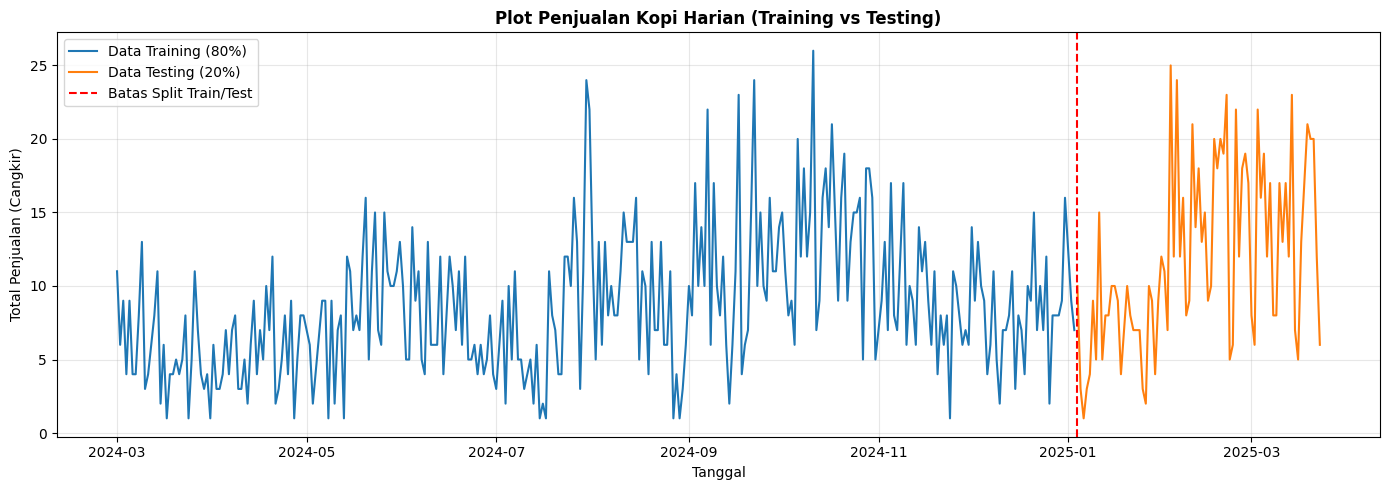

In [ ]:
import matplotlib.pyplot as plt

# Ambil tanggal pertama pada data testing sebagai posisi garis pemisah
split_date = test['Date'].iloc[0]

plt.figure(figsize=(14, 5))

# Plot data training dan testing dengan warna terpisah
plt.plot(train['Date'], train['total_penjualan'], label='Data Training (80%)', color='tab:blue')
plt.plot(test['Date'], test['total_penjualan'], label='Data Testing (20%)', color='tab:orange')

# Menambahkan garis vertikal pemisah
plt.axvline(x=split_date, color='red', linestyle='--', linewidth=1.5, label='Batas Split Train/Test')

# Kustomisasi judul dan label sumbu
plt.title('Plot Penjualan Kopi Harian (Training vs Testing)', fontsize=12, fontweight='bold')
plt.xlabel('Tanggal', fontsize=10)
plt.ylabel('Total Penjualan (Cangkir)', fontsize=10)
plt.grid(True, alpha=0.3)
plt.legend(loc='upper left')

plt.tight_layout()
plt.show()

In [ ]:
from statsmodels.tsa.stattools import adfuller

def uji_adf(data, nama):
    hasil = adfuller(data.dropna())
    print(f'--- {nama} ---')
    print(f'ADF Statistic : {hasil[0]:.6f}')
    print(f'p-value       : {hasil[1]:.6f}')
    if hasil[1] < 0.05:
        print('Kesimpulan    : Stasioner')
    else:
        print('Kesimpulan    : Tidak stasioner')

uji_adf(train['total_penjualan'], 'total_penjualan')

--- total_penjualan ---
ADF Statistic : -3.329178
p-value       : 0.013624
Kesimpulan    : Stasioner


/tmp/ipykernel_1964/2426997286.py:4: FutureWarning: adfuller currently returns a plain tuple whose length depends on the store and autolag arguments. In release 0.16 or after July 2027, whichever is later, the default behavior will switch to always returning an ADFullerResult. Set result_object=True to switch now, or result_object=False to keep the current behavior and silence this warning.
  hasil = adfuller(data.dropna())


In [ ]:
from statsmodels.tsa.stattools import kpss
import warnings
warnings.filterwarnings('ignore')

def uji_kpss(data, nama):
    # regression='c' digunakan untuk menguji stasioneritas di sekitar nilai rata-rata (mean)
    hasil = kpss(data.dropna(), regression='c', nlags='auto')
    print(f'--- Uji KPSS: {nama} ---')
    print(f'KPSS Statistic      : {hasil[0]:.6f}')
    print(f'p-value             : {hasil[1]:.6f}')
    print(f'Lags used           : {hasil[2]}')
    print(f'Critical Value (5%) : {hasil[3]['5%']}')

    # Kriteria Keputusan
    if hasil[1] < 0.05:
        print('Kesimpulan     : Tidak stasioner (Tolak H0)')
    else:
        print('Kesimpulan     : Stasioner (Gagal tolak H0)')

# Eksekusi fungsi pada data training
uji_kpss(train['total_penjualan'], 'total_penjualan')

--- Uji KPSS: total_penjualan ---
KPSS Statistic      : 1.094948
p-value             : 0.010000
Lags used           : 9
Critical Value (5%) : 0.463
Kesimpulan     : Tidak stasioner (Tolak H0)


In [ ]:
# 1. Melakukan Differencing Pertama (d = 1)
train['diff_1'] = train['total_penjualan'].diff()

# 2. Uji ADF Ulang
uji_adf(train['diff_1'].dropna(), 'total_penjualan (Differencing 1)')

# 3. Uji KPSS Ulang
uji_kpss(train['diff_1'].dropna(), 'total_penjualan (Differencing 1)')

--- total_penjualan (Differencing 1) ---
ADF Statistic : -13.347657
p-value       : 0.000000
Kesimpulan    : Stasioner
--- Uji KPSS: total_penjualan (Differencing 1) ---
KPSS Statistic      : 0.110899
p-value             : 0.100000
Lags used           : 58
Critical Value (5%) : 0.463
Kesimpulan     : Stasioner (Gagal tolak H0)


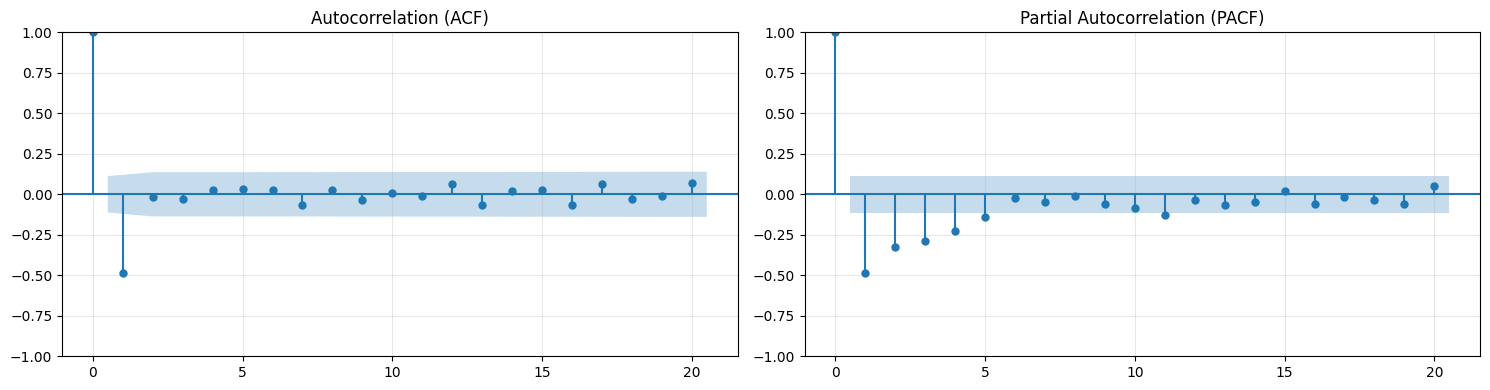

In [ ]:
import matplotlib.pyplot as plt
from statsmodels.graphics.tsaplots import plot_acf, plot_pacf

# Pastikan data differencing dibuang nilai NaN-nya
diff_data = train['diff_1'].dropna()
fig, axes = plt.subplots(1, 2, figsize=(15, 4))

# 1. Plot ACF (untuk menentukan calon orde q / MA)
plot_acf(diff_data, ax=axes[0], lags=20, title='Autocorrelation (ACF)')
axes[0].grid(True, alpha=0.3)

# 2. Plot PACF (untuk menentukan calon orde p / AR)
plot_pacf(diff_data, ax=axes[1], lags=20, title='Partial Autocorrelation (PACF)', method='ywm')
axes[1].grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

In [ ]:
from statsmodels.tsa.arima.model import ARIMA
import pandas as pd
import warnings
warnings.filterwarnings('ignore')

hasil_kopi = []
for p in range(5):
    for q in range(3):
        if p == 0 and q == 0:
            continue
        try:
            # Gunakan d=1 sesuai hasil uji stasioneritas
            model = ARIMA(train['total_penjualan'], order=(p, 1, q)).fit()
            hasil_kopi.append([f'ARIMA({p},1,{q})', model.aic, model.bic])
        except:
            continue
# Susun dalam DataFrame dan urutkan berdasarkan AIC terkecil
df_hasil = pd.DataFrame(hasil_kopi, columns=['Model', 'AIC', 'BIC']).sort_values('AIC').reset_index(drop=True)
df_hasil

,Model,AIC,BIC
0,"ARIMA(0,1,1)",1734.127327,1741.554793
1,"ARIMA(0,1,2)",1736.097693,1747.238891
2,"ARIMA(1,1,1)",1736.100008,1747.241206
3,"ARIMA(2,1,1)",1737.763376,1752.618307
4,"ARIMA(1,1,2)",1738.016087,1752.871018
5,"ARIMA(4,1,2)",1739.031905,1765.028034
6,"ARIMA(3,1,1)",1739.386294,1757.954958
7,"ARIMA(2,1,2)",1739.697973,1758.266637
8,"ARIMA(4,1,1)",1740.680098,1762.962495
9,"ARIMA(3,1,2)",1741.273159,1763.555556


In [ ]:
import numpy as np
import pandas as pd
from statsmodels.tsa.arima.model import ARIMA
from sklearn.metrics import mean_absolute_error, mean_squared_error

# 1. Pilih beberapa kandidat model dengan AIC/BIC terbaik dari tahap sebelumnya
kandidat_model = [(0, 1, 1), (0, 1, 2), (1, 1, 1), (2, 1, 1), (1, 1, 2)]
hasil_evaluasi_testing = []

for order in kandidat_model:
    # Train/Fit model pada data training
    model = ARIMA(train['total_penjualan'], order=order).fit()

    # Predict/Forecast langsung ke data testing
    pred = model.forecast(steps=len(test))

    # Hitung metrik evaluasi pada data testing
    mae = mean_absolute_error(test['total_penjualan'], pred)
    rmse = np.sqrt(mean_squared_error(test['total_penjualan'], pred))

    # Hitung MAPE (dengan menambahkan 1e-8 agar aman dari pembagian dengan 0 pada tanggal libur)
    mape = np.mean(np.abs((test['total_penjualan'] - pred) / (test['total_penjualan'] + 1e-8))) * 100

    hasil_evaluasi_testing.append({
        'Model': f"ARIMA{order}",
        'MAE (Testing)': round(mae, 4),
        'RMSE (Testing)': round(rmse, 4),
        'MAPE (%)': round(mape, 2)
    })

# 2. Tampilkan tabel perbandingan kemampuan prediksi di data testing
df_evaluasi = pd.DataFrame(hasil_evaluasi_testing).sort_values('MAPE (%)').reset_index(drop=True)
df_evaluasi

,Model,MAE (Testing),RMSE (Testing),MAPE (%)
0,"ARIMA(0, 1, 1)",5.3689,6.8729,59.19
1,"ARIMA(0, 1, 2)",5.3627,6.8644,59.24
2,"ARIMA(1, 1, 1)",5.3632,6.8652,59.24
3,"ARIMA(1, 1, 2)",5.3516,6.8487,59.36
4,"ARIMA(2, 1, 1)",5.3376,6.8293,59.50


In [ ]:
import numpy as np
import pandas as pd
from statsmodels.tsa.arima.model import ARIMA
from sklearn.metrics import mean_absolute_error, mean_squared_error

# 1. Daftar kandidat model terbaik
kandidat_model = [(0, 1, 1), (0, 1, 2), (1, 1, 1), (1, 1, 2), (2, 1, 1)]
hasil_evaluasi_testing = []

# 2. Hitung metrik evaluasi pada data testing
for order in kandidat_model:
    model = ARIMA(train['total_penjualan'], order=order).fit()
    pred = model.forecast(steps=len(test))

    y_true = test['total_penjualan'].values
    y_pred = pred.values

    # Metrik Absolut
    mae = mean_absolute_error(y_true, y_pred)
    rmse = np.sqrt(mean_squared_error(y_true, y_pred))

    # Metrik Persentase yang Lebih Stabil (WAPE & sMAPE)
    wape = (np.sum(np.abs(y_true - y_pred)) / np.sum(y_true)) * 100
    smape = np.mean(2 * np.abs(y_pred - y_true) / (np.abs(y_true) + np.abs(y_pred))) * 100

    hasil_evaluasi_testing.append({
        'Model': f"ARIMA{order}",
        'MAE': round(mae, 4),
        'RMSE': round(rmse, 4),
        'WAPE (%)': round(wape, 2),
        'sMAPE (%)': round(smape, 2)
    })

# 3. Tampilkan tabel perbandingan
df_evaluasi = pd.DataFrame(hasil_evaluasi_testing).sort_values('WAPE (%)').reset_index(drop=True)
df_evaluasi

,Model,MAE,RMSE,WAPE (%),sMAPE (%)
0,"ARIMA(2, 1, 1)",5.3376,6.8293,44.34,48.32
1,"ARIMA(1, 1, 2)",5.3516,6.8487,44.45,48.47
2,"ARIMA(0, 1, 2)",5.3627,6.8644,44.54,48.59
3,"ARIMA(1, 1, 1)",5.3632,6.8652,44.55,48.59
4,"ARIMA(0, 1, 1)",5.3689,6.8729,44.60,48.65


# BERDASARKAN TIME OF DAY

In [ ]:
# Pivot data berdasarkan Date dan Time_of_Day
df_tod = df.groupby(['Date', 'Time_of_Day']).size().unstack(fill_value=0).reset_index()
df_tod.columns.name = None
df_tod = df_tod.sort_values('Date').reset_index(drop=True)

# Tampilkan 5 baris pertama
df_tod.head()

,Date,Afternoon,Morning,Night
0,2024-03-01,6,1,4
1,2024-03-02,2,3,1
2,2024-03-03,2,2,5
3,2024-03-04,1,3,0
4,2024-03-05,1,1,7


In [ ]:
print(df_tod.shape[0])

381


In [ ]:
# Aggregate per Date & Time_of_Day
df_tod = df.groupby(['Date', 'Time_of_Day']).size().unstack(fill_value=0).reset_index()
df_tod['Date'] = pd.to_datetime(df_tod['Date'])

# Terapkan reindex tanggal lengkap
df_tod_complete = df_tod.set_index('Date').reindex(full_range, fill_value=0).reset_index()
df_tod_complete.rename(columns={'index': 'Date'}, inplace=True)

# Filter hari yang MINIMAL SALAH SATU sesinya 0 (Pagi=0 ATAU Siang=0 ATAU Malam=0)
zero_any_session = df_tod_complete[
    (df_tod_complete['Morning'] == 0) |
    (df_tod_complete['Afternoon'] == 0) |
    (df_tod_complete['Night'] == 0)
]

print("Jumlah hari yang ada sesi bernilai 0:", len(zero_any_session))
zero_any_session.head(10)

Jumlah hari yang ada sesi bernilai 0: 159


Time_of_Day,Date,Afternoon,Morning,Night
3,2024-03-04,1,3,0
5,2024-03-06,4,0,0
6,2024-03-07,2,2,0
8,2024-03-09,11,0,2
9,2024-03-10,0,1,2
10,2024-03-11,3,1,0
11,2024-03-12,3,3,0
12,2024-03-13,6,2,0
14,2024-03-15,0,1,1
15,2024-03-16,5,0,1


In [ ]:
zero_all_session = df_tod_complete[
    (df_tod_complete['Morning'] == 0) &
    (df_tod_complete['Afternoon'] == 0) &
    (df_tod_complete['Night'] == 0)
]

print("Jumlah hari yang 3 sesinya 0 semua:", len(zero_all_session))
zero_all_session

Jumlah hari yang 3 sesinya 0 semua: 7


Time_of_Day,Date,Afternoon,Morning,Night
61,2024-05-01,0,0,0
64,2024-05-04,0,0,0
65,2024-05-05,0,0,0
271,2024-11-27,0,0,0
306,2025-01-01,0,0,0
324,2025-01-19,0,0,0
328,2025-01-23,0,0,0
